# 03 · Antigüedad de inventario — la definición operativa del negocio

**Predicción de devoluciones de inventario y ajuste de la demanda neta**
Grupo 5 — Maestría en Inteligencia Artificial Aplicada, UDLA

Los cuadernos 01 y 02 construyeron la variable objetivo cruzando el reporte de despachos con el
inventario: los días se contaban desde que la unidad llegaba al local según el despacho.

El área de planificación usa otra definición, más simple:

> **Una unidad que lleva 60 días o más en la misma bodega de un distribuidor es una devolución
> esperada.**

Se mide solo sobre el inventario diario. No interviene el despacho. Este cuaderno la implementa,
la valida contra un listado real del negocio y la compara con la anterior.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt

from src import antiguedad as A
from src.config import REPORTES, UMBRAL_DIAS, VENTANA_LIMPIA

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 60)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True,
                     "grid.alpha": .3, "font.size": 10})
PROC = RAIZ / "data" / "processed"
print(f"Umbral del negocio: {UMBRAL_DIAS} días")

Umbral del negocio: 60 días


## 1. Por qué cambia la definición

| | Cuadernos 01-02 | Este cuaderno |
|---|---|---|
| Fuentes | despachos + inventario + ventas | **solo inventario** |
| Inicio del conteo | llegada al local según el despacho | **primera aparición en la bodega** |
| Unidades perdidas | 8 % no rastreable (sin cruce despacho-inventario) | ninguna |
| Origen | construida por nosotros | **la que usa planificación** |

La segunda es preferible por tres razones: es la que el negocio reconoce, no depende de emparejar
dos fuentes, y elimina el problema de las unidades no rastreables.

## 2. Estadías en el canal

Se parte de la tabla de estadías —cada tramo `(imei, bodega, desde, hasta)`— y se excluyen las
bodegas operadas por Telefónica, que el reporte del negocio no cuenta como inventario del canal.

In [2]:
stock = pd.read_parquet(PROC / "v2_stock.parquet", columns=["fecha"])
est   = pd.read_parquet(PROC / "v2_estadias.parquet")

faltantes = A.dias_faltantes(stock)
canal = A.estadias_canal(est, faltantes)
print(f"Estadías totales : {len(est):,}")
print(f"En bodega de canal: {len(canal):,}  ({len(canal)/len(est):.0%})")
canal.head(3)[["imei", "bodega_nombre", "marca", "desde", "hasta",
               "dias_en_bodega", "supera_umbral", "antiguedad_dudosa"]]

Estadías totales : 764,009
En bodega de canal: 185,398  (24%)


,imei,bodega_nombre,marca,desde,hasta,dias_en_bodega,supera_umbral,antiguedad_dudosa
0,010603008188418,CENTRO CORPORATIVO EKOPARK,ALCATEL,2025-06-25,2025-06-25,1,False,False
1,011468001026141,CENTRO CORPORATIVO EKOPARK,NOKIA,2025-06-25,2025-06-25,1,False,False
2,012325003201438,CENTRO CORPORATIVO EKOPARK,SAMSUNG,2025-06-25,2025-06-25,1,False,False


### Qué se excluye y por qué

El criterio se derivó comparando nuestro cálculo contra el listado real del negocio. Sin filtrar,
marcábamos 185 unidades de más; **176 de ellas estaban en bodegas de Telefónica**.

Hay un matiz que conviene conocer: `CAVS SAN MARINO` es tienda propia y se excluye, pero
`CAVS AE SALESLAND MACHALA` la opera un agente externo y sí cuenta. La marca `AE` es la que
distingue. Está pendiente de confirmar con el cliente.

In [3]:
propias = est[~est.imei.isin(canal.imei) | ~est.index.isin(canal.index)]
excl = (est[~est.index.isin(canal.index)]
        .bodega_nombre.value_counts().head(10).rename("estadías"))
excl.to_frame()

,estadías
bodega_nombre,
BODEGA CENTRAL TELEFONICA,169768
BODEGA MATERIA PRIMA / PRODUCCIÓN,129531
TIENDA VIRTUAL (SSP),63622
FALTANTES PRINCIPAL (USIM),27501
.1 ACCOUNT R1,19521
REF. OPERACIONES EMP,16774
BODEGA CENTRAL,12188
CAVS QUICENTRO,7425
AE CORPORATIVO ROMERO RYRTECH MALL EL FORTIN,7057


## 3. Control de calidad — los huecos del inventario

El inventario es diario, pero faltan días. Un hueco no parte una estadía, pero sí puede truncar su
inicio: si la unidad llegó durante el hueco, su antigüedad arranca tarde y queda subestimada.

Cada estadía lleva una bandera `antiguedad_dudosa` cuando empieza justo después de un hueco de más
de dos días, o cuando atraviesa uno.

In [4]:
print(f"Días del período sin snapshot: {len(faltantes)}")
f = pd.Series(faltantes)
grupos = f.diff().dt.days.ne(1).cumsum()
huecos = pd.DataFrame([{"desde": x.min().date(), "hasta": x.max().date(), "días": len(x)}
                       for _, x in f.groupby(grupos)])
huecos.sort_values("días", ascending=False)

Días del período sin snapshot: 38


,desde,hasta,días
10,2025-11-13,2025-11-25,13
9,2025-11-01,2025-11-10,10
11,2025-11-28,2025-11-30,3
6,2025-02-22,2025-02-23,2
8,2025-07-12,2025-07-13,2
4,2024-12-06,2024-12-06,1
3,2024-05-05,2024-05-05,1
2,2024-03-23,2024-03-23,1
1,2024-02-24,2024-02-24,1
0,2024-02-03,2024-02-03,1


**Noviembre de 2025 concentra 26 de los 38 días perdidos.** El resto son días sueltos que apenas
afectan: un hueco de un día introduce como mucho un día de error sobre un umbral de 60.

In [5]:
m = canal[canal.madura]
print(f"Estadías evaluables      : {len(m):,}")
print(f"Con antigüedad dudosa    : {m.antiguedad_dudosa.sum():,} ({m.antiguedad_dudosa.mean():.1%})")
print("")
print("Motivo de la duda:")
print(f"  empiezan tras un hueco : {(m.inicio_tras_hueco & (m.dias_hueco_previo > 2)).sum():,}")
print(f"  atraviesan un hueco    : {(m.dias_sin_dato_dentro > 2).sum():,}")

Estadías evaluables      : 178,918
Con antigüedad dudosa    : 12,680 (7.1%)

Motivo de la duda:
  empiezan tras un hueco : 1,721
  atraviesan un hueco    : 11,975


## 4. Validación contra un listado real del negocio

El área de planificación entregó el listado de equipos Samsung con 60 o más días de antigüedad al
**13 de enero de 2026**: 367 unidades. Es la prueba de si nuestro cálculo reproduce el suyo.

In [6]:
RUTA_LISTADO = Path.home() / "Downloads" / "prueba.xlsx"
CORTE = pd.Timestamp("2026-01-13")

if RUTA_LISTADO.exists():
    lis = pd.read_excel(RUTA_LISTADO, engine="calamine")
    IMEIS = set(lis.IMEI.astype(str).str.extract(r"(\d{14,})")[0].dropna())
    print(f"Listado del negocio: {len(IMEIS)} equipos Samsung al {CORTE:%d-%m-%Y}")
else:
    IMEIS = set(); print("Listado no disponible; se omite la validación")

Listado del negocio: 367 equipos Samsung al 13-01-2026


In [7]:
if IMEIS:
    tabla = A.validar(canal[canal.marca == "SAMSUNG"], IMEIS, CORTE)
    total = tabla.values.sum(); aciertos = tabla.iloc[0, 0] + tabla.iloc[1, 1]
    display(tabla)
    print(f"Coincidencia global        : {aciertos}/{total} = {aciertos/total:.1%}")
    print(f"Del listado que capturamos : {tabla.iloc[1,1]}/{tabla.iloc[1].sum()} = "
          f"{tabla.iloc[1,1]/tabla.iloc[1].sum():.1%}")
    print(f"Marcados de más            : {tabla.iloc[0,1]}")

,<60 dias,60+ dias
fuera del listado,1101,9
en el listado,59,308


Coincidencia global        : 1409/1477 = 95.4%
Del listado que capturamos : 308/367 = 83.9%
Marcados de más            : 9


### Los que no capturamos son, otra vez, noviembre

De los 59 equipos del listado que nuestro cálculo deja por debajo de 60 días, **42 llevan la
bandera de antigüedad dudosa**. Su fecha de inicio se concentra en el 26 de noviembre de 2025 —el
primer día con snapshot después del hueco de trece días—, lo que les impone un techo artificial de
48 días.

No es un error del método: es la consecuencia medida de los datos que faltan.

In [8]:
if IMEIS:
    s = canal[(canal.marca == "SAMSUNG") & (canal.desde <= CORTE) & (canal.hasta >= CORTE)].copy()
    s["antiguedad"] = (CORTE - s.desde).dt.days + 1
    fn = s[s.imei.isin(IMEIS) & (s.antiguedad < 60)]
    print(f"No capturados: {len(fn)}   ·   con bandera de duda: {fn.antiguedad_dudosa.sum()}")
    display(fn.desde.dt.strftime("%Y-%m-%d").value_counts().sort_index()
              .head(6).rename("estadías que empiezan ese día").to_frame())

No capturados: 59   ·   con bandera de duda: 42


,estadías que empiezan ese día
desde,
2025-11-26,30
2025-11-27,3
2025-12-01,9
2025-12-02,3
2025-12-06,1
2025-12-07,1


## 5. La serie mensual

In [9]:
panel = A.panel_mensual(canal, por=("marca",))
panel = panel[panel.mes >= VENTANA_LIMPIA]
serie = panel.groupby("mes").agg(ingresaron=("ingresaron", "sum"),
                                 superan=("superan", "sum"),
                                 valor=("valor", "sum"))
serie["tasa_%"] = (serie.superan / serie.ingresaron.replace(0, np.nan) * 100).round(1)
serie.tail(18)

,ingresaron,superan,valor,tasa_%
mes,,,,
2025-04-01,10266.0,1063.0,369025.41,10.4
2025-05-01,9749.0,879.0,299677.06,9.0
2025-06-01,7222.0,1700.0,478182.31,23.5
2025-07-01,9619.0,1707.0,360919.60,17.7
2025-08-01,7492.0,1062.0,277112.19,14.2
2025-09-01,5273.0,913.0,223448.35,17.3
2025-10-01,4818.0,2146.0,569968.60,44.5
2025-11-01,1751.0,1001.0,264430.33,57.2
2025-12-01,3825.0,1112.0,234820.57,29.1


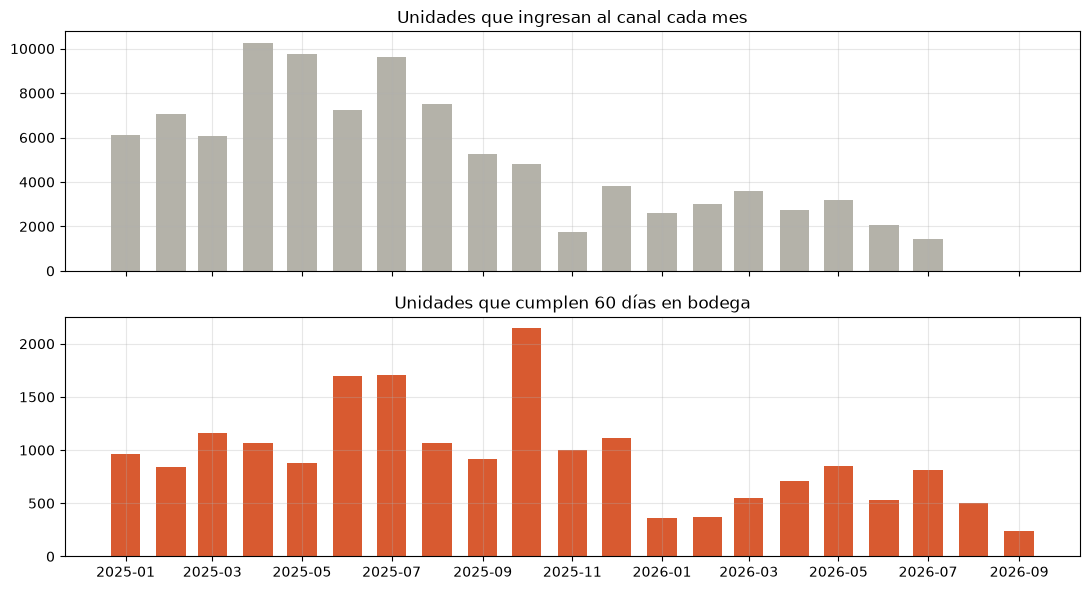

In [10]:
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax[0].bar(serie.index, serie.ingresaron, width=20, color="#B4B2A9")
ax[0].set_title("Unidades que ingresan al canal cada mes")
ax[1].bar(serie.index, serie.superan, width=20, color="#D85A30")
ax[1].set_title(f"Unidades que cumplen {UMBRAL_DIAS} días en bodega")
plt.tight_layout(); plt.savefig(REPORTES / "figuras" / "v3_serie_mensual.png", dpi=120); plt.show()

In [11]:
pm = (canal[canal.madura].groupby("marca")
        .agg(estadias=("imei", "size"), superan=("supera_umbral", "sum"),
             dias_mediana=("dias_en_bodega", "median"), valor=("precio", "sum"))
        .assign(tasa=lambda x: (x.superan / x.estadias * 100).round(1))
        .sort_values("estadias", ascending=False))
pm[pm.estadias >= 500]

,estadias,superan,dias_mediana,valor,tasa
marca,,,,,
HONOR,65332,5408,9.0,14485152.50,8.3
SAMSUNG,46180,9334,18.0,11739674.75,20.2
XIAOMI,35707,5818,13.0,5042915.71,16.3
APPLE,15704,3708,22.0,13751214.10,23.6
OTRA,6153,2191,34.0,1276785.60,35.6
INFINIX,4808,1224,4.0,702402.55,25.5
MOTOROLA,2836,1154,44.0,688091.24,40.7
REALME,1094,417,40.0,182778.13,38.1
NOKIA,701,285,57.0,93083.23,40.7


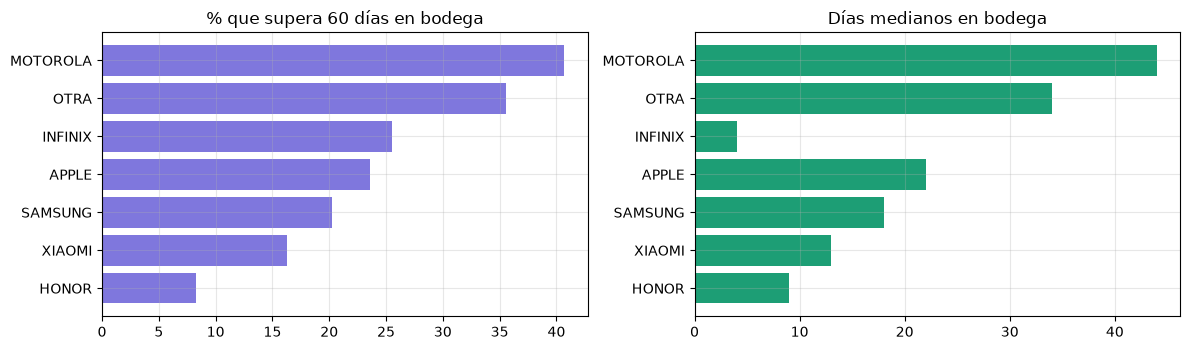

In [12]:
g = pm[pm.estadias >= 2000].sort_values("tasa")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].barh(g.index, g.tasa, color="#7F77DD")
ax[0].set_title(f"% que supera {UMBRAL_DIAS} días en bodega")
ax[1].barh(g.index, g.dias_mediana, color="#1D9E75")
ax[1].set_title("Días medianos en bodega")
plt.tight_layout(); plt.savefig(REPORTES / "figuras" / "v3_marcas.png", dpi=120); plt.show()

## 6. La foto mensual — lo que el negocio ve en su reporte

La serie anterior es un **flujo**: cuántas unidades cruzan el umbral cada mes. El reporte
operativo del cliente es una **foto**: cuántas unidades tienen 60 o más días al cierre de cada mes.

Las dos son útiles y responden preguntas distintas. El modelo usa el flujo, porque es lo que se
resta del pedido; la foto sirve para conciliar con el negocio.

In [13]:
foto = A.foto_mensual(canal)
foto = foto[foto.corte >= VENTANA_LIMPIA]
foto.tail(12).round(1)

,corte,en_canal,con_umbral,valor,pct
20,2025-09-30,6256,1123,269318.5,18.0
21,2025-10-31,6863,2337,570957.4,34.1
22,2025-11-30,4933,2388,516270.1,48.4
23,2025-12-31,3365,1241,251075.1,36.9
24,2026-01-31,2835,701,114006.6,24.7
25,2026-02-28,3200,546,99840.3,17.1
26,2026-03-31,3882,761,300934.0,19.6
27,2026-04-30,3991,1137,436265.3,28.5
28,2026-05-31,3611,752,226605.4,20.8
29,2026-06-30,3353,935,334238.2,27.9


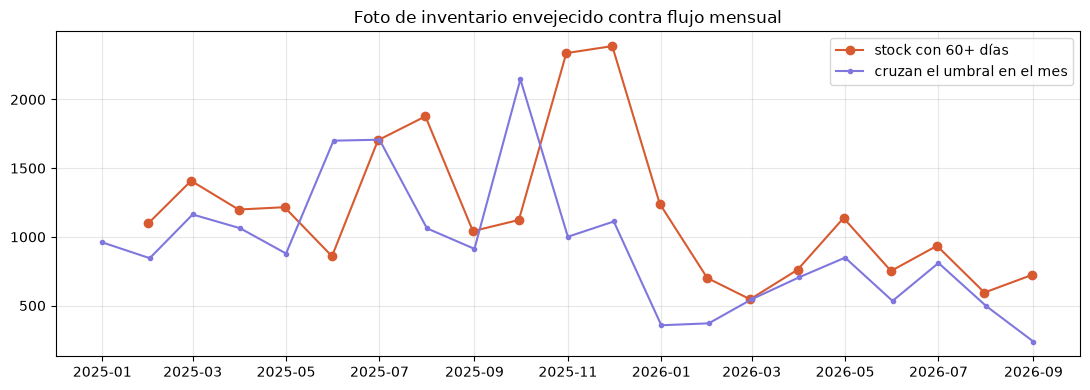

In [14]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(foto.corte, foto.con_umbral, marker="o", color="#D85A30", label="stock con 60+ días")
ax.plot(serie.index, serie.superan, marker=".", color="#7F77DD", label="cruzan el umbral en el mes")
ax.legend(); ax.set_title("Foto de inventario envejecido contra flujo mensual")
plt.tight_layout(); plt.savefig(REPORTES / "figuras" / "v3_foto_vs_flujo.png", dpi=120); plt.show()

## 7. Comparación con la definición anterior

In [15]:
try:
    viejo = pd.read_parquet(PROC / "v2_panel_marca_mes.parquet")
    viejo = viejo[viejo.mes >= VENTANA_LIMPIA].groupby("mes").devueltas.sum()
    cmp = pd.DataFrame({"def. despacho (cuaderno 01)": viejo,
                        "def. negocio (este cuaderno)": serie.superan}).dropna()
    display(cmp.astype(int))
    print(f"\nTotal con la definición anterior : {cmp.iloc[:,0].sum():,.0f}")
    print(f"Total con la definición del negocio: {cmp.iloc[:,1].sum():,.0f}")
except FileNotFoundError:
    print("Panel anterior no disponible")

,def. despacho (cuaderno 01),def. negocio (este cuaderno)
mes,,
2025-01-01,46,960
2025-02-01,59,845
2025-03-01,753,1163
2025-04-01,1646,1063
2025-05-01,583,879
2025-06-01,1018,1700
2025-07-01,1123,1707
2025-08-01,838,1062
2025-09-01,1656,913



Total con la definición anterior : 12,982
Total con la definición del negocio: 17,914


La definición del negocio produce **más eventos**, y era previsible: cuenta cada estadía en cada
bodega, de modo que una unidad que pasa 60 días en un local, se mueve a otro y vuelve a pasar 60
cuenta dos veces. Desde el punto de vista del negocio es correcto — fue inventario parado en dos
sitios distintos.

## 8. Panel para el modelo

In [16]:
for por, nom in [(("marca",), "marca"), (("marca", "bodega_nombre"), "marca_bodega")]:
    p = A.panel_mensual(canal, por=por)
    p = p[p.mes >= VENTANA_LIMPIA]
    p.to_parquet(PROC / f"v3_panel_{nom}_mes.parquet", index=False)
    print(f"{nom:14s} {len(p):>7,} filas | {p.mes.nunique()} meses | "
          f"densidad {(p.superan>0).mean():.1%} | {int(p.superan.sum()):,} eventos")

# versión sin las estadías cuya antigüedad depende de un hueco de inventario
p_lim = A.panel_mensual(canal, por=("marca",), excluir_dudosas=True)
p_lim = p_lim[p_lim.mes >= VENTANA_LIMPIA]
p_lim.to_parquet(PROC / "v3_panel_marca_mes_sin_dudosas.parquet", index=False)
print(f"{'marca (limpio)':14s} {len(p_lim):>7,} filas | {int(p_lim.superan.sum()):,} eventos")

canal.to_parquet(PROC / "v3_estadias_canal.parquet", index=False)
A.resumen(canal).to_frame("valor")

marca              294 filas | 21 meses | densidad 53.1% | 19,460 eventos


marca_bodega    47,628 filas | 21 meses | densidad 9.2% | 19,460 eventos
marca (limpio)     294 filas | 11,677 eventos


,valor
estadias en canal,185398.0000
evaluables (maduras),178918.0000
superan el umbral,29667.0000
tasa,0.1658
con antiguedad dudosa,12680.0000
dias en bodega (mediana),13.0000
dias en bodega (p90),78.0000


---

## Conclusión

**La definición del negocio se reproduce con 95,4 % de coincidencia** sobre un listado real de 367
equipos. De las diferencias, las 59 que no capturamos se explican por el hueco de noviembre de
2025 —42 llevan la bandera correspondiente— y solo 9 unidades las marcamos de más.

**Es la definición que conviene adoptar.** No necesita el reporte de despachos, no pierde el 8 % de
unidades no rastreables, y es la que el área de planificación ya utiliza y entiende.

**Dos salidas para el modelado**, en `data/processed/`:

- `v3_panel_marca_mes.parquet` — la serie completa
- `v3_panel_marca_mes_sin_dudosas.parquet` — sin las estadías cuya antigüedad depende de un hueco

Entrenar con ambas y comparar es la forma de medir cuánto pesa el problema de cobertura. Si los
resultados difieren poco, el hueco de noviembre no compromete el modelo; si difieren, hay un
argumento cuantificado para insistir en la solicitud de datos.